# Preprocessing, data audit, and feature engineering

This notebook prepares the Singapore HDB rental data for the modeling stage. It removes additional exact duplicates from training, preserves every test transaction, records data-quality findings, and builds target-free structural, location, and macroeconomic features. Reusable logic lives in `src/data_preprocessing.py` so this notebook stays focused on decisions and evidence.

## 1. Setup

The project root is detected from either the repository root or the `notebooks` directory. Raw files remain unchanged under `data/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'PROJECT_PLAN.md').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'PROJECT_PLAN.md').exists():
    raise FileNotFoundError('Run this notebook from the project root or notebooks directory.')

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.eda_analysis import (
    load_new_auxiliary, rent_correlations, summarize_outliers, tertiary_distance_summary,
)

from src.data_preprocessing import (
    SmoothedGroupTargetEncoder,
    audit_raw_data,
    canonicalize_flat_type,
    load_raw_data,
    run_pipeline,
)

DATA_DIR = PROJECT_ROOT / 'data'
PROCESSED_DIR = DATA_DIR / 'processed'
AUDIT_DIR = PROJECT_ROOT / 'artifacts' / 'data_audit'
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', context='notebook')

## 2. Source tables and raw audit

The project has two modeling tables and six pipeline auxiliary sources plus three new sources under review. The submission template is listed separately because it defines the required output format and does not supply model features. The raw audit records each source table's shape, missing values, duplicate rows, time coverage, and join quality.

In [2]:
datasets = load_raw_data(DATA_DIR)
raw_audit = audit_raw_data(datasets)
new_auxiliary = load_new_auxiliary(DATA_DIR)

source_catalog = {
    'train': ('Primary modeling data', 'Training transactions', 'train.csv', 'Model fitting and validation target'),
    'test': ('Primary modeling data', 'Test transactions', 'test.csv', 'Rows requiring rent predictions'),
    'hdb': ('Location reference tables', 'HDB block reference', 'auxiliary/sg-hdb-block.csv', 'Block attributes and coordinates'),
    'mrt': ('Location reference tables', 'MRT station reference', 'auxiliary/sg-mrt-stations.csv', 'Transit-distance features'),
    'schools': ('Location reference tables', 'School reference', 'auxiliary/sg-schools.csv', 'School-distance features'),
    'malls': ('Location reference tables', 'Shopping mall reference', 'auxiliary/sg-shopping-malls.csv', 'Retail-distance features'),
    'coe': ('Economic time series', 'COE price history', 'auxiliary/sg-coe-prices.csv', 'Monthly vehicle-market indicators'),
    'stocks': ('Economic time series', 'Stock price history', 'auxiliary/sg-stock-prices.csv', 'Monthly financial-market indicators'),
    'example_submission': ('Submission template', 'Example submission', 'example-submission.csv', 'Required prediction-file structure'),
}

inventory_rows = []
for key, (section, source_table, source_file, purpose) in source_catalog.items():
    stats = raw_audit['datasets'][key]
    inventory_rows.append({
        'section': section,
        'source table': source_table,
        'source file': source_file,
        'purpose': purpose,
        'rows': stats['rows'],
        'columns': stats['columns'],
        'exact duplicate rows': stats['exact_duplicate_rows'],
        'missing columns': ', '.join(stats['missing_values']) or 'none',
    })
for key, label, file, purpose in [
    ('cpi', 'Consumer price index', 'auxiliary/sg-cpi.csv', 'Candidate monthly inflation context'),
    ('tertiary', 'Tertiary institutions', 'auxiliary/sg-tertiary-institutions.csv', 'Candidate campus proximity'),
]:
    frame = new_auxiliary[key]
    inventory_rows.append({
        'section': 'New auxiliary sources', 'source table': label, 'source file': file,
        'purpose': purpose, 'rows': len(frame), 'columns': len(frame.columns),
        'exact duplicate rows': int(frame.duplicated().sum()),
        'missing columns': ', '.join(frame.columns[frame.isna().any()]) or 'none',
    })
inventory_rows.append({
    'section': 'New auxiliary sources', 'source table': 'Rail line geometry',
    'source file': 'auxiliary/sg-rail-lines.geojson',
    'purpose': 'Candidate route proximity; static snapshot',
    'rows': len(new_auxiliary['rail']['features']), 'columns': 'GeoJSON',
    'exact duplicate rows': 'not assessed', 'missing columns': 'none in checked properties',
})
source_inventory = pd.DataFrame(inventory_rows)

for section in [
    'Primary modeling data',
    'Location reference tables',
    'Economic time series',
    'New auxiliary sources',
    'Submission template',
]:
    display(Markdown(f'### {section}'))
    display(
        source_inventory.loc[
            source_inventory['section'].eq(section),
            ['source table', 'source file', 'purpose', 'rows', 'columns', 'exact duplicate rows', 'missing columns'],
        ].set_index('source table')
    )

### Primary modeling data

,source file,purpose,rows,columns,exact duplicate rows,missing columns
source table,,,,,,
Training transactions,train.csv,Model fitting and validation target,150000,11,425,none
Test transactions,test.csv,Rows requiring rent predictions,50000,10,5508,none


### Location reference tables

,source file,purpose,rows,columns,exact duplicate rows,missing columns
source table,,,,,,
HDB block reference,auxiliary/sg-hdb-block.csv,Block attributes and coordinates,9464,11,0,none
MRT station reference,auxiliary/sg-mrt-stations.csv,Transit-distance features,243,8,0,none
School reference,auxiliary/sg-schools.csv,School-distance features,337,14,0,none
Shopping mall reference,auxiliary/sg-shopping-malls.csv,Retail-distance features,113,3,0,none


### Economic time series

,source file,purpose,rows,columns,exact duplicate rows,missing columns
source table,,,,,,
COE price history,auxiliary/sg-coe-prices.csv,Monthly vehicle-market indicators,539,8,0,none
Stock price history,auxiliary/sg-stock-prices.csv,Monthly financial-market indicators,91642,9,0,"OPEN, HIGH, LOW, CLOSE, ADJUSTED_CLOSE, VOLUME"


### New auxiliary sources

,source file,purpose,rows,columns,exact duplicate rows,missing columns
source table,,,,,,
Consumer price index,auxiliary/sg-cpi.csv,Candidate monthly inflation context,67,4,0,none
Tertiary institutions,auxiliary/sg-tertiary-institutions.csv,Candidate campus proximity,13,4,0,none
Rail line geometry,auxiliary/sg-rail-lines.geojson,Candidate route proximity; static snapshot,1397,GeoJSON,not assessed,none in checked properties


### Submission template

,source file,purpose,rows,columns,exact duplicate rows,missing columns
source table,,,,,,
Example submission,example-submission.csv,Required prediction-file structure,50000,2,0,none


### New source checks and timing

The CPI file has one complete row per month. The institution file supplies current campus coordinates. The rail GeoJSON supplies route geometry with no historical opening dates. These three sources are inspected here as candidate additions. They are **not yet included** in the saved Parquet features or the feature dictionary. CPI values for the approval month may not be available at prediction time; test lagged values separately. The campus and route snapshots cannot establish historical access.

In [3]:
cpi = new_auxiliary['cpi']
tertiary = new_auxiliary['tertiary']
new_source_checks = pd.DataFrame([
    {'source': 'CPI', 'coverage': f"{cpi['MONTH'].min()} to {cpi['MONTH'].max()}", 'records': len(cpi), 'check': 'Unique, consecutive months; positive complete values'},
    {'source': 'Tertiary institutions', 'coverage': ', '.join(f'{kind}: {count}' for kind, count in tertiary['type'].value_counts().items()), 'records': len(tertiary), 'check': 'Unique names; valid Singapore coordinates'},
    {'source': 'Rail lines', 'coverage': str(new_auxiliary['rail_types']), 'records': len(new_auxiliary['rail']['features']), 'check': f"Geometry: {new_auxiliary['rail_geometries']}"},
])
display(new_source_checks)
display(tertiary_distance_summary(datasets['hdb'], tertiary).round(2))

,source,coverage,records,check
0,CPI,2021-01 to 2026-07,67,"Unique, consecutive months; positive complete ..."
1,Tertiary institutions,"university: 6, polytechnic: 5, arts: 2",13,Unique names; valid Singapore coordinates
2,Rail lines,"{'MRT': 1279, 'LRT': 115, 'RAILWAY': 3}",1397,"Geometry: {'LineString': 1274, 'MultiLineStrin..."


,group,institutions,median_nearest_km,blocks_within_2km,block_count
0,any tertiary,13,3.20,2590,9464
1,university,6,4.51,1118,9464
2,polytechnic,5,4.41,1633,9464


In [4]:
core = raw_audit['core']
coverage = pd.DataFrame(raw_audit['hdb_join_coverage']).T
overview = pd.Series({
    'Training period': f"{core['train_date_min']} to {core['train_date_max']}",
    'Test period': f"{core['test_date_min']} to {core['test_date_max']}",
    'Overlapping months': ', '.join(core['overlap_months']),
    'March 2025 training rows': core['march_2025_train_rows'],
    'March 2025 test rows': core['march_2025_test_rows'],
    'Low-rent rows below SGD 1,000': raw_audit['target']['low_rent_rows_below_1000'],
    'Invalid lease-date rows': core['invalid_lease_date_rows'],
}, name='value')
display(overview.to_frame())
display(coverage.style.format({'coverage_rate': '{:.1%}'}))
auxiliary_checks = pd.json_normalize(raw_audit['auxiliary_validation'], sep=' / ').T
auxiliary_checks.columns = ['value']
display(auxiliary_checks)

,value
Training period,2021-01 to 2025-03
Test period,2025-03 to 2026-07
Overlapping months,2025-03
March 2025 training rows,3032
March 2025 test rows,380
"Low-rent rows below SGD 1,000",374
Invalid lease-date rows,1


,rows,matched_rows,unmatched_rows,coverage_rate
train_raw,150000.000000,119219.000000,30781.000000,79.5%
train_normalized,150000.000000,150000.000000,0.000000,100.0%
test_raw,50000.000000,39518.000000,10482.000000,79.0%
test_normalized,50000.000000,50000.000000,0.000000,100.0%


,value
hdb / normalized_address_keys_unique,True
hdb / coordinates_valid,True
hdb / max_floor_sentinel_rows,11
hdb / completion_year_sentinel_rows,11
hdb / postal_code_nil_rows,285
hdb / unexpected_max_floor_values,0
hdb / unexpected_completion_year_values,0
points_of_interest / mrt / rows,243
points_of_interest / mrt / coordinates_valid,True
points_of_interest / mrt / duplicate_coordinate_pairs,51


### Audit decisions

- `FURNISHED` is always `yes` and `FEE` is always zero. The pipeline asserts those conditions before removing the columns.
- Training uses both `4 room` and `4-room` style labels. The canonical form uses a hyphen.
- The pipeline removes 425 additional training rows that are identical across every original column, including `MONTHLY_RENT`. It keeps the first occurrence and its original `ROW_ID`. Repeated predictor profiles with different rents remain because they are distinct observed outcomes. Every test row remains for submission.
- One transaction has a lease commencement year after its approval month. Its source year is retained, its derived age is missing, and `INVALID_LEASE_DATE_FLAG` marks the issue.
- Eleven HDB blocks use `-1` as a sentinel for both maximum floor and completion year. Those values become missing, dedicated flags preserve the information, and block age remains missing instead of becoming an impossible value. The 285 HDB blocks whose postal code is `NIL` receive the same explicit treatment.
- Address normalization raises the HDB-block join from partial coverage to complete coverage. The join is validated as many transactions to one block.

In [5]:
train_rows = len(datasets['train'])
repeated_groups = core['repeated_predictor_groups']
conflicting_groups = core['repeated_groups_with_different_rents']
duplicate_summary = pd.DataFrame([
    {
        'metric': 'Exact duplicate rows',
        'count': core['train_exact_duplicates'],
        'context': f"{core['train_exact_duplicates'] / train_rows:.2%} of training rows",
        'meaning': 'Additional rows identical across all predictors and MONTHLY_RENT; the first occurrence is not counted.',
        'pipeline treatment': 'Remove each additional copy; retain the first row and its original ROW_ID.',
    },
    {
        'metric': 'Repeated predictor groups',
        'count': repeated_groups,
        'context': 'Unique predictor combinations appearing at least twice',
        'meaning': 'Rows match on every input column; MONTHLY_RENT is excluded from the grouping.',
        'pipeline treatment': 'Retain because these groups can contain distinct rent outcomes.',
    },
    {
        'metric': 'Repeated groups with different rents',
        'count': conflicting_groups,
        'context': f"{conflicting_groups / repeated_groups:.1%} of repeated predictor groups",
        'meaning': 'The same observed inputs occur with at least two MONTHLY_RENT values.',
        'pipeline treatment': 'Retain all rows because the recorded targets differ.',
    },
    {
        'metric': 'Rows in repeated groups with different rents',
        'count': core['rows_in_conflicting_repeated_groups'],
        'context': f"{core['rows_in_conflicting_repeated_groups'] / train_rows:.1%} of training rows",
        'meaning': 'Training records that belong to the repeated groups described in the row above.',
        'pipeline treatment': 'Retain all rows because they represent distinct recorded outcomes.',
    },
])

train_flat_counts = datasets['train']['FLAT_TYPE'].value_counts()
test_flat_counts = datasets['test']['FLAT_TYPE'].value_counts()
raw_flat_labels = sorted(set(train_flat_counts.index) | set(test_flat_counts.index))
canonical_flat_labels = canonicalize_flat_type(pd.Series(raw_flat_labels)).tolist()
flat_label_mapping = pd.DataFrame({
    'raw label': raw_flat_labels,
    'canonical label': canonical_flat_labels,
    'training rows': [int(train_flat_counts.get(label, 0)) for label in raw_flat_labels],
    'test rows': [int(test_flat_counts.get(label, 0)) for label in raw_flat_labels],
})

display(Markdown('### Duplicate diagnostics'))
display(duplicate_summary.style.format({'count': '{:,.0f}'}).hide(axis='index'))
display(Markdown('### Flat-type label normalization'))
display(flat_label_mapping.style.format({'training rows': '{:,.0f}', 'test rows': '{:,.0f}'}).hide(axis='index'))

### Duplicate diagnostics

metric,count,context,meaning,pipeline treatment
Exact duplicate rows,425,0.28% of training rows,Additional rows identical across all predictors and MONTHLY_RENT; the first occurrence is not counted.,Remove each additional copy; retain the first row and its original ROW_ID.
Repeated predictor groups,"13,434",Unique predictor combinations appearing at least twice,Rows match on every input column; MONTHLY_RENT is excluded from the grouping.,Retain because these groups can contain distinct rent outcomes.
Repeated groups with different rents,"13,191",98.2% of repeated predictor groups,The same observed inputs occur with at least two MONTHLY_RENT values.,Retain all rows because the recorded targets differ.
Rows in repeated groups with different rents,"28,493",19.0% of training rows,Training records that belong to the repeated groups described in the row above.,Retain all rows because they represent distinct recorded outcomes.


### Flat-type label normalization

raw label,canonical label,training rows,test rows
1 room,1-room,8,0
1-room,1-room,34,12
2 room,2-room,532,0
2-room,2-room,"2,566","1,436"
3 room,3-room,"12,092",0
3-room,3-room,"36,932","16,425"
4 room,4-room,"13,391",0
4-room,4-room,"40,688","18,045"
5 room,5-room,"9,308",0
5-room,5-room,"26,215","11,530"


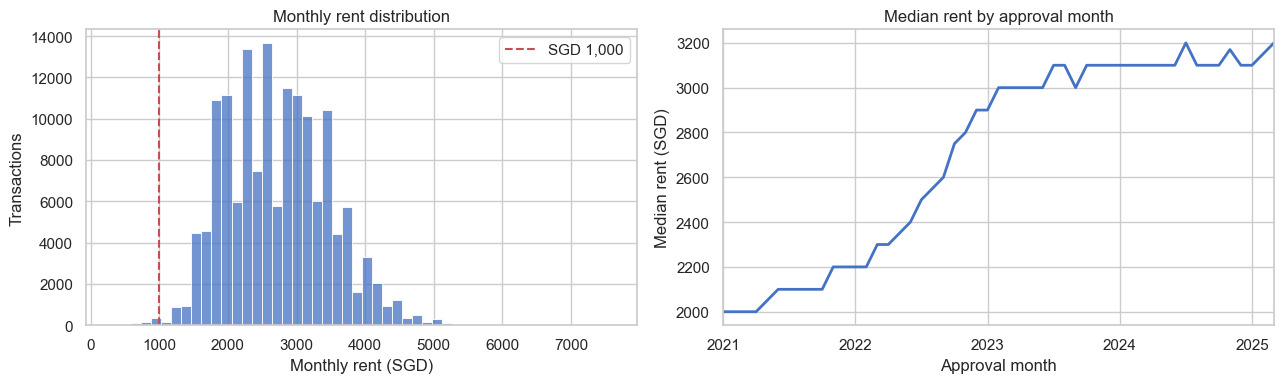

In [6]:
raw_train = datasets['train'].copy()
raw_train['RENT_APPROVAL_DATE'] = pd.to_datetime(raw_train['RENT_APPROVAL_DATE'], format='%Y-%m')
monthly_target = raw_train.groupby('RENT_APPROVAL_DATE').agg(
    transactions=('MONTHLY_RENT', 'size'),
    median_rent=('MONTHLY_RENT', 'median'),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(raw_train['MONTHLY_RENT'], bins=50, ax=axes[0], color='#4472C4')
axes[0].axvline(1000, color='#C44E52', linestyle='--', linewidth=1.5, label='SGD 1,000')
axes[0].set(title='Monthly rent distribution', xlabel='Monthly rent (SGD)', ylabel='Transactions')
axes[0].legend()
monthly_target['median_rent'].plot(ax=axes[1], color='#4472C4', linewidth=2)
axes[1].set(title='Median rent by approval month', xlabel='Approval month', ylabel='Median rent (SGD)')
plt.tight_layout()
plt.show()

## 3. Run the preprocessing pipeline

Structural and calendar features use only fields available on each transaction. Geospatial features are calculated once for each HDB block and then joined back to the transactions. Distances use the Haversine formula. Raffles Place MRT provides a reproducible CBD proxy from the supplied coordinates.

Open and planned MRT features remain separate. Planned entries in the supplied file describe future line connectivity at existing stations, so they are never counted as open stations. Primary-school features include records whose level starts at primary school.

In [7]:
result = run_pipeline(DATA_DIR, PROCESSED_DIR, AUDIT_DIR)
train_features = result['train']
test_features = result['test']
feature_dictionary = result['feature_dictionary']
audit = result['audit']

pd.Series({
    'Raw training rows': audit['cleaning']['raw_training_rows'],
    'Exact duplicate training rows removed': audit['cleaning']['exact_duplicate_training_rows_removed'],
    'Training rows after deduplication': len(train_features),
    'Test rows': len(test_features),
    'Delivered predictors': test_features.shape[1],
    'HDB blocks enriched': audit['feature_engineering']['hdb_blocks_enriched'],
    'Fixed stock universe size': audit['feature_engineering']['stock_universe_size'],
}, name='value').to_frame()

,value
Raw training rows,150000
Exact duplicate training rows removed,425
Training rows after deduplication,149575
Test rows,50000
Delivered predictors,78
HDB blocks enriched,9464
Fixed stock universe size,42


## 4. Macroeconomic timing choices

COE rounds are aggregated by month for Categories A and B. Premium uses the mean across rounds, while demand is total bids divided by total quota.

The stock composite uses Singapore-listed symbols present at the beginning of the training period. Monthly returns use adjusted closes. The features include the cross-sectional median return, the share of positive returns, and a DBS/OCBC/UOB bank composite. This fixed universe avoids changes caused only by later listings.

Columns ending in `_CURRENT` can use information observed later in the approval month and are labeled as competition-only. `_LAG1` and `_LAGGED_3M_MEAN` features use earlier months and support deployment-style evaluation. Early months retain expected missing history and receive explicit availability flags.

In [8]:
feature_groups = (
    feature_dictionary
    .groupby(['group', 'availability'], dropna=False)
    .size()
    .rename('columns')
    .reset_index()
)
display(feature_groups)
display(result['monthly']['coe'].head(5))
display(result['monthly']['stocks'].head(5))

,group,availability,columns
0,HDB block,derived,1
1,HDB block,static diagnostic,3
2,HDB block,static snapshot,8
3,core,observed,7
4,core structural,derived,6
5,core temporal,derived,6
6,core temporal,observed,1
7,geospatial,static snapshot,18
8,key,observed,1
9,macro COE,competition-only current month,4


,RENT_APPROVAL_DATE,COE_A_PREMIUM_CURRENT,COE_A_DEMAND_RATIO_CURRENT,COE_B_PREMIUM_CURRENT,COE_B_DEMAND_RATIO_CURRENT,COE_A_PREMIUM_LAG1,COE_A_PREMIUM_LAGGED_3M_MEAN,COE_A_DEMAND_RATIO_LAG1,COE_A_DEMAND_RATIO_LAGGED_3M_MEAN,COE_B_PREMIUM_LAG1,COE_B_PREMIUM_LAGGED_3M_MEAN,COE_B_DEMAND_RATIO_LAG1,COE_B_DEMAND_RATIO_LAGGED_3M_MEAN,COE_CURRENT_AVAILABLE,COE_LAG1_AVAILABLE,COE_LAGGED_3M_AVAILABLE
0,2021-01-01,42055.0,1.342146,49550.5,1.339539,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0
1,2021-02-01,41500.5,1.299776,46396.0,1.206897,42055.0,NaN,1.342146,NaN,49550.5,NaN,1.339539,NaN,1,1,0
2,2021-03-01,43292.5,1.331641,46001.0,1.240996,41500.5,NaN,1.299776,NaN,46396.0,NaN,1.206897,NaN,1,1,0
3,2021-04-01,47620.0,1.411168,56749.5,1.624347,43292.5,42282.666667,1.331641,1.324521,46001.0,47315.833333,1.240996,1.262477,1,1,1
4,2021-05-01,44901.5,1.385123,59045.0,1.426039,47620.0,44137.666667,1.411168,1.347528,56749.5,49715.500000,1.624347,1.357413,1,1,1


,RENT_APPROVAL_DATE,STOCK_SG_MARKET_RETURN_CURRENT,STOCK_SG_POSITIVE_BREADTH_CURRENT,STOCK_BANK_RETURN_CURRENT,STOCK_SG_MARKET_RETURN_LAG1,STOCK_SG_MARKET_RETURN_LAGGED_3M_MEAN,STOCK_SG_POSITIVE_BREADTH_LAG1,STOCK_SG_POSITIVE_BREADTH_LAGGED_3M_MEAN,STOCK_BANK_RETURN_LAG1,STOCK_BANK_RETURN_LAGGED_3M_MEAN,STOCK_CURRENT_AVAILABLE,STOCK_LAG1_AVAILABLE,STOCK_LAGGED_3M_AVAILABLE
0,2021-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0
1,2021-02-01,0.007974,0.571429,0.058008,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0
2,2021-03-01,0.050842,0.809524,0.069129,0.007974,NaN,0.571429,NaN,0.058008,NaN,1,1,0
3,2021-04-01,0.028364,0.785714,0.038295,0.050842,NaN,0.809524,NaN,0.069129,NaN,1,1,0
4,2021-05-01,-0.016587,0.285714,0.010128,0.028364,0.02906,0.785714,0.722222,0.038295,0.055144,1,1,1


## 5. Final quality checks

The saved training and test predictors have the same schema. Training keeps the original order and `ROW_ID` for the first occurrence of each exact row; test retains every row in original order. `MONTHLY_RENT` appears only in training and is unchanged for all retained records. Expected missing values come from the flagged invalid lease date, documented HDB sentinels, or unavailable early macro history. Each missingness pattern must match its explicit flag exactly. The pipeline also compares every value and dtype after the Parquet round trip. No target-derived feature is stored.

,result
raw_train_rows,150000
train_rows_after_exact_deduplication,149575
train_exact_duplicate_rows_removed,425
test_rows,50000
predictor_columns,78
retained_train_target_unchanged,True
train_test_schema_aligned,True
retained_train_row_order_preserved,True
test_row_order_preserved,True
infinite_numeric_values,0


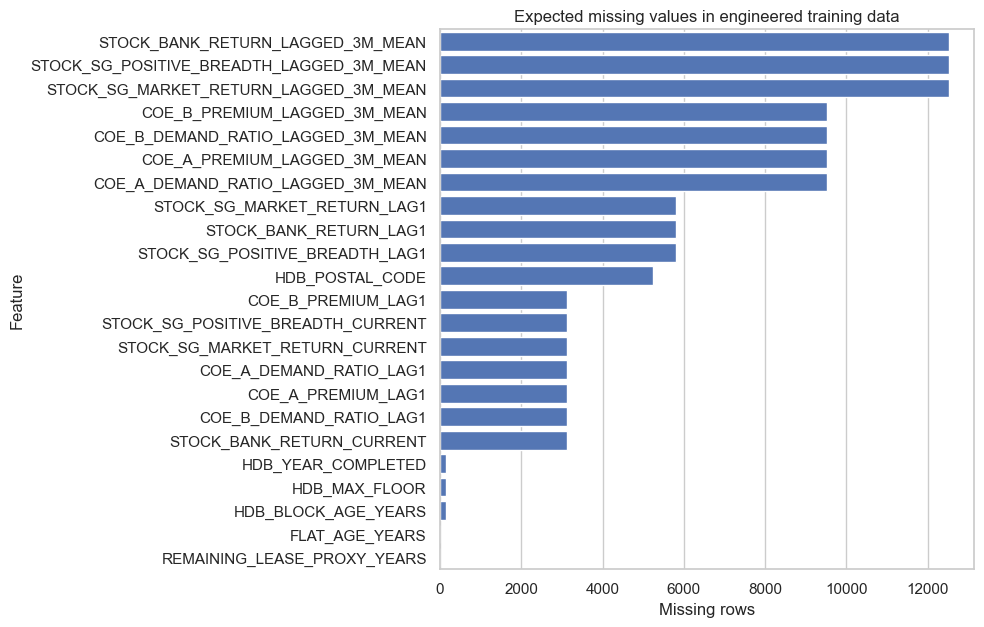

,missing_rows
STOCK_BANK_RETURN_LAGGED_3M_MEAN,12515
STOCK_SG_POSITIVE_BREADTH_LAGGED_3M_MEAN,12515
STOCK_SG_MARKET_RETURN_LAGGED_3M_MEAN,12515
COE_B_PREMIUM_LAGGED_3M_MEAN,9514
COE_B_DEMAND_RATIO_LAGGED_3M_MEAN,9514
COE_A_PREMIUM_LAGGED_3M_MEAN,9514
COE_A_DEMAND_RATIO_LAGGED_3M_MEAN,9514
STOCK_SG_MARKET_RETURN_LAG1,5809
STOCK_BANK_RETURN_LAG1,5809
STOCK_SG_POSITIVE_BREADTH_LAG1,5809


In [9]:
validation = audit['final_validation']
display(pd.Series({
    key: value
    for key, value in validation.items()
    if key != 'expected_missing_values'
}, name='result').to_frame())

missing = train_features.isna().sum().sort_values(ascending=False)
missing = missing[missing.gt(0)]
fig, ax = plt.subplots(figsize=(10, max(3, 0.28 * len(missing))))
sns.barplot(x=missing.values, y=missing.index, ax=ax, color='#4472C4')
ax.set(title='Expected missing values in engineered training data', xlabel='Missing rows', ylabel='Feature')
plt.tight_layout()
plt.show()
display(missing.rename('missing_rows').to_frame())

## 6. Leakage-safe target feature interface

`SmoothedGroupTargetEncoder` is available for a later modeling notebook. Call `fit_transform` only on the training rows of a temporal fold; it produces leave-one-out values for those rows and stores a fold-specific mapping. Call `transform` on validation or test rows. Unseen groups use the training-fold global mean. The preprocessing pipeline does not fit this encoder or save its outputs.

In [10]:
encoder_interface = pd.DataFrame([
    {'method': 'fit_transform(X_train, y_train)', 'use': 'Leave-one-out values for one training fold'},
    {'method': 'transform(X_validation)', 'use': 'Apply the fitted fold mapping with global fallback'},
    {'method': 'transform(X_test)', 'use': 'Apply the final training-only mapping'},
])
display(encoder_interface)

,method,use
0,"fit_transform(X_train, y_train)",Leave-one-out values for one training fold
1,transform(X_validation),Apply the fitted fold mapping with global fall...
2,transform(X_test),Apply the final training-only mapping


## 7. Saved artifacts

The Parquet files are ready for model-specific preprocessing. Scaling, imputation, categorical encoding, feature selection, and ablation remain part of the modeling stage.

In [11]:
artifact_table = pd.DataFrame([
    {'artifact': name, 'path': str(path.relative_to(PROJECT_ROOT))}
    for name, path in result['paths'].items()
])
display(artifact_table)
display(feature_dictionary.head(15))

,artifact,path
0,train,data\processed\train_features.parquet
1,test,data\processed\test_features.parquet
2,audit,artifacts\data_audit\audit_summary.json
3,feature_dictionary,artifacts\data_audit\feature_dictionary.csv


,feature,dtype,role,group,availability,source,definition,expected_missingness
0,ROW_ID,int64,identifier,key,observed,generated,Zero-based source row position; unchanged thro...,none
1,RENT_APPROVAL_DATE,datetime64[ns],feature,core temporal,observed,train/test,Source YYYY-MM approval value converted to the...,none
2,TOWN,string,feature,core,observed,train/test,"Source town after lowercase conversion, trimmi...",none
3,BLOCK,string,feature,core,observed,train/test,Source HDB block identifier after lowercase co...,none
4,STREET,string,feature,core,observed,train/test,"Source street after lowercase conversion, trim...",none
5,FLAT_TYPE,string,feature,core,observed,train/test,Canonical flat label: 1-room through 5-room or...,none
6,FLAT_MODEL,string,feature,core,observed,train/test,"Source flat model after lowercase conversion, ...",none
7,FLOOR_AREA_SQM,float64,feature,core,observed,train/test,Source floor area in square metres; must be po...,none
8,LEASE_COMMENCE_DATE,int64,feature,core,observed,train/test,Source lease commencement year retained unchan...,none
9,APPROVAL_YEAR,int16,feature,core temporal,derived,train/test,Calendar year extracted from RENT_APPROVAL_DATE.,none


## 8. Using the features with different prediction methods

The processed files preserve a general-purpose feature set. Each model family needs its own preprocessing step. `ROW_ID` identifies source records and must never be used as a predictor. `RENT_APPROVAL_DATE` should also be removed after using the derived year, month, quarter, month index, and sine/cosine features. The table below calculates the current categorical width and the effect of full one-hot encoding.

In [12]:
model_features = train_features.drop(columns=['ROW_ID', 'MONTHLY_RENT'])
categorical_columns = model_features.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
datetime_columns = model_features.select_dtypes(include=['datetime', 'datetimetz']).columns.tolist()
numeric_columns = [
    column for column in model_features.columns
    if column not in categorical_columns + datetime_columns
]

categorical_profile = pd.DataFrame({
    'feature': categorical_columns,
    'training levels': [train_features[column].nunique(dropna=False) for column in categorical_columns],
    'test levels': [test_features[column].nunique(dropna=False) for column in categorical_columns],
    'unseen test levels': [
        len(
            set(test_features[column].dropna().astype(str).unique())
            - set(train_features[column].dropna().astype(str).unique())
        )
        for column in categorical_columns
    ],
}).sort_values('training levels', ascending=False).reset_index(drop=True)

one_hot_indicator_columns = int(categorical_profile['training levels'].sum())
high_cardinality_location = {'ADDRESS_KEY', 'HDB_POSTAL_CODE', 'BLOCK'}
reduced_one_hot_columns = int(
    categorical_profile.loc[
        ~categorical_profile['feature'].isin(high_cardinality_location),
        'training levels',
    ].sum()
)
encoding_summary = pd.DataFrame([
    {'quantity': 'Model columns before encoding', 'columns': model_features.shape[1]},
    {'quantity': 'Categorical columns', 'columns': len(categorical_columns)},
    {'quantity': 'Numeric columns', 'columns': len(numeric_columns)},
    {'quantity': 'Raw datetime columns to remove', 'columns': len(datetime_columns)},
    {
        'quantity': 'Theoretical indicators from full one-hot encoding',
        'columns': one_hot_indicator_columns,
    },
    {
        'quantity': 'Total columns after full one-hot encoding and removing raw date',
        'columns': len(numeric_columns) + one_hot_indicator_columns,
    },
    {
        'quantity': 'Total after excluding address, postal code, and block from one-hot encoding',
        'columns': len(numeric_columns) + reduced_one_hot_columns,
    },
])

display(encoding_summary.style.format({'columns': '{:,.0f}'}).hide(axis='index'))
display(categorical_profile.style.format({
    'training levels': '{:,.0f}',
    'test levels': '{:,.0f}',
    'unseen test levels': '{:,.0f}',
}).hide(axis='index'))

quantity,columns
Model columns before encoding,77
Categorical columns,10
Numeric columns,66
Raw datetime columns to remove,1
Theoretical indicators from full one-hot encoding,"22,068"
Total columns after full one-hot encoding and removing raw date,"22,134"
"Total after excluding address, postal code, and block from one-hot encoding",886


feature,training levels,test levels,unseen test levels
ADDRESS_KEY,"9,406","8,940",50
HDB_POSTAL_CODE,"9,122","8,665",50
BLOCK,"2,720","2,660",11
STREET,576,573,0
HDB_SUBZONE,156,156,0
HDB_PLANNING_AREA,31,31,0
TOWN,26,26,0
FLAT_MODEL,20,19,0
FLAT_TYPE,6,6,0
HDB_REGION,5,5,0


### Model-specific preparation

The one-hot totals above are theoretical full-width estimates. They count every distinct training level, including an explicitly represented missing category, with no dropped reference level and no rare-category grouping. A fitted encoder can produce fewer columns when `drop`, `min_frequency`, or `max_categories` is used. Before any categorical encoder, replace `pd.NA` with the reserved string `__MISSING__`. Build the vocabulary on the training portion of each temporal fold and reserve `__UNKNOWN__` for validation or test levels absent from that vocabulary. For frequency encoding, use frequency zero for unseen categories.

| Prediction method | Categorical features | Numeric values and missingness | Recommended use in this project |
|---|---|---|---|
| **CatBoost** | Replace categorical `pd.NA` with `__MISSING__`, then pass all ten categorical columns directly. CatBoost handles previously unseen strings without a manually fitted one-hot vocabulary. Do not one-hot encode high-cardinality location fields. | Keep numeric missing values and their availability flags; scaling is unnecessary. | Strong primary model because it can learn from town, street, block, postal code, and address without expanding them into thousands of indicators. |
| **LightGBM or XGBoost** | Use verified native categorical support with reserved missing and unknown levels, or one-hot encode only lower-cardinality fields. For frequency-encoded address, postal code, or block, map unseen levels to frequency zero. | Native tree missing-value handling is suitable; scaling is unnecessary. | Good boosted-tree alternatives. Validate the exact categorical configuration and unseen-category handling used by the installed library. |
| **Ridge or Elastic Net** | Replace missing categories with `__MISSING__`, reserve `__UNKNOWN__`, and one-hot encode lower-cardinality fields with `handle_unknown='ignore'`. Use a sparse matrix. Exclude overlapping high-cardinality identifiers or retain only one compact location representation. | Median-impute numeric values, keep every missingness flag, and standardize numeric columns. | Useful transparent baseline. Full one-hot encoding is unnecessarily wide because address, postal code, and block describe overlapping location information. |
| **Random Forest or Extra Trees** | Apply the same `__MISSING__` and `__UNKNOWN__` policy, then use a reduced categorical set with frequency encoding or carefully validated categorical codes. Map unseen frequency-encoded levels to zero. | Impute numeric missing values and keep flags; scaling is unnecessary. | Feasible baseline, though boosted trees are usually more efficient for this combination of structured and high-cardinality data. |
| **k-nearest neighbours or kernel SVR** | Apply the same missing/unknown policy and keep only low-cardinality categories after one-hot encoding. Remove high-cardinality identifiers. | Impute and standardize every numeric feature. | Secondary experiments only: distance methods are sensitive to feature scale and sparse high-dimensional inputs, and they are expensive at this training size. |
| **Neural network** | Use learned embeddings for high-cardinality fields, reserving ID 0 for missing and ID 1 for unknown levels. Use small one-hot vectors or embeddings for low-cardinality fields. | Standardize numeric inputs and supply missingness flags or masks. | Appropriate only with careful tuning; it adds complexity without guaranteeing an improvement over boosted trees. |

### Leakage and feature-selection rules

1. Fit every encoder, imputer, scaler, frequency map, or category vocabulary on the training portion of each temporal fold. Apply that fitted transformation to the validation portion.
2. Use `SmoothedGroupTargetEncoder` only inside a training fold. Never calculate target encodings once on the full training dataset.
3. Compare feature groups through temporal ablation: core and calendar features first, then HDB and geospatial features, then `_LAG1` and `_LAGGED_3M_MEAN` macro features. Test `_CURRENT` macro features separately because they are competition-only.
4. Treat `ADDRESS_KEY`, `HDB_POSTAL_CODE`, and `BLOCK` as overlapping location identifiers. A model does not automatically benefit from including all three representations.
5. Select the final representation using validation RMSE across time folds. Column count alone does not establish whether a feature helps.

## 9. EDA: feature relationships and unusual rents

These views describe the cleaned training rows. Correlations are univariate associations and can reflect common time trends or differences between flat types. The IQR screen uses flat type and approval year groups, so price changes across years do not create a single fixed cutoff. All flagged rows stay in the model data; any target-based filtering decision must be fitted and evaluated inside development folds.

feature,pearson_r,spearman_rho,missing_rows
MONTH_INDEX,+0.535,+0.564,0
APPROVAL_YEAR,+0.517,+0.554,0
FLOOR_AREA_SQM,+0.330,+0.319,0
HDB_MAX_FLOOR,+0.290,+0.226,159
FLAT_AGE_YEARS,-0.178,-0.166,1
NEAREST_MALL_KM,-0.083,-0.088,0
NEAREST_OPEN_MRT_KM,-0.084,-0.086,0
DISTANCE_TO_RAFFLES_PLACE_KM,-0.092,-0.060,0
NEAREST_PRIMARY_SCHOOL_KM,-0.011,-0.014,0


metric,rows
Retained training rows,"149,575"
"Low rents below SGD 1,000",374
Within-group IQR low flags,"1,977"
Within-group IQR high flags,"1,408"
Any IQR flag,"3,385"


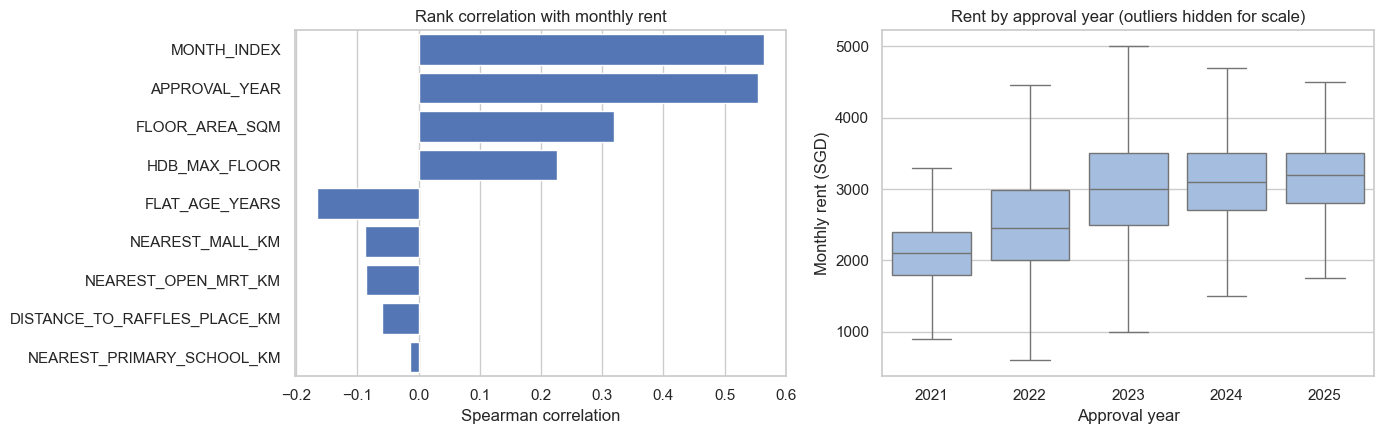

In [13]:
eda_features = [
    'FLOOR_AREA_SQM', 'FLAT_AGE_YEARS', 'HDB_MAX_FLOOR',
    'DISTANCE_TO_RAFFLES_PLACE_KM', 'NEAREST_OPEN_MRT_KM',
    'NEAREST_PRIMARY_SCHOOL_KM', 'NEAREST_MALL_KM',
    'APPROVAL_YEAR', 'MONTH_INDEX',
]
correlation_table = rent_correlations(train_features, eda_features)
outlier_summary, outlier_rows = summarize_outliers(datasets['train'])
display(correlation_table.style.format({'pearson_r': '{:+.3f}', 'spearman_rho': '{:+.3f}'}).hide(axis='index'))
display(outlier_summary.style.format({'rows': '{:,.0f}'}).hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=correlation_table, x='spearman_rho', y='feature', ax=axes[0], color='#4472C4')
axes[0].set(title='Rank correlation with monthly rent', xlabel='Spearman correlation', ylabel='')
sns.boxplot(data=outlier_rows, x='approval_year', y='MONTHLY_RENT', ax=axes[1],
            showfliers=False, color='#9BBCE8')
axes[1].set(title='Rent by approval year (outliers hidden for scale)',
            xlabel='Approval year', ylabel='Monthly rent (SGD)')
plt.tight_layout()
plt.show()

### EDA handoff for the slide deck

Report the exact number of flagged rows, the correlation method, and the grouping rule. Explain that low rents below SGD 1,000 are observed values with unknown tenancy context. The new CPI, campus, and rail files are candidates for a later feature-group ablation. Test each group on temporal development folds before adding it to the production preprocessing output.